# 07 - Eindresultaat: de minimapvideo en het rapport

Dit laatste notebook draait de hele pijplijn één keer met het actieve model en de standaardinstellingen, en schrijft het
eindresultaat weg:

* de **minimapvideo**: de clip met boxen, track-ID's en teruggeprojecteerde veldlijnen, naast de 2D-minimap;
* de twee **csv-bestanden** met alle posities (`tracks`) en de bal met het balbezit per frame (`frames`);
* de **analyses** (afstand, snelheidszones, heatmaps) en de **systeemevaluatie** tegen de ground truth;
* een **rapport** in markdown dat alles samenvat.

Alles komt in `streamlit/output/`. Het notebook roept dezelfde functies aan als de Streamlit-app; de uitleg van elke stap
staat in notebook 02 tot 06. Met een detectiecache voor het actieve model duurt dit ongeveer een halve minuut.

In [1]:
import contextlib
import io
import sys
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, Video, display

ROOT = Path("..")                                   # final_upload/
sys.path.insert(0, str(ROOT / "streamlit"))         # the code of the app
from core.paths import DEFAULT_WEIGHTS, OUTPUT_DIR   # noqa: E402
from core.pipeline import DEFAULT_BALL_CONF, DEFAULT_IMGSZ   # noqa: E402
from run_all import build_parser, run_all            # noqa: E402

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11, "axes.titleweight": "bold"})
print(f"Model: {DEFAULT_WEIGHTS.name} | imgsz {DEFAULT_IMGSZ} | baldrempel {DEFAULT_BALL_CONF}")

Model: psg_vs_inter_CV.pt | imgsz 1280 | baldrempel 0.2


### Met welk model draait dit notebook?

Alle notebooks gebruiken het **actieve model** `models/psg_vs_inter_CV.pt`. Dat is het meegeleverde referentiemodel, of
het model dat notebook 01 getraind en op die plek gezet heeft. De cel hieronder zegt welk van de twee het is.

In [2]:
# The active model: the delivered reference model, or a model trained and installed by notebook 01.
import hashlib
import json
from pathlib import Path

ACTIVE_MODEL = Path("..") / "models" / "psg_vs_inter_CV.pt"
if not ACTIVE_MODEL.exists():
    raise FileNotFoundError("Er is geen model in models/psg_vs_inter_CV.pt. Draai eerst notebook 01 met een volledige "
                            "training (MODE = 'full', NVIDIA-GPU aanbevolen), of zet het meegeleverde model terug.")
_ref = json.loads((Path("..") / "data" / "results" / "referentie_model.json").read_text(encoding="utf-8"))
IS_REFERENCE = hashlib.md5(ACTIVE_MODEL.read_bytes()).hexdigest() == _ref["md5"]
if IS_REFERENCE:
    print("Actief model: het meegeleverde referentiemodel. De tekst en de cijfers in dit notebook horen bij dit model.")
else:
    print("Actief model: een ANDER model dan het referentiemodel (bijvoorbeeld hertraind in notebook 01).\n"
          "- De code rekent alles opnieuw uit voor dit model.\n"
          "- De begeleidende tekst beschrijft het referentiemodel: de cijfers in de uitvoer kunnen dus van de tekst afwijken.\n"
          "- Zonder detectiecache voor dit model draait YOLO eerst over de clip: seconden op een GPU, minuten per "
          "instelling op een CPU.")

Actief model: het meegeleverde referentiemodel. De tekst en de cijfers in dit notebook horen bij dit model.


## 1. De pijplijn draaien en alles wegschrijven

`run_all` doet vier stappen: de minimap met de csv-bestanden en de video, de analyses, de systeemevaluatie en het rapport.

In [3]:
t0 = time.time()
log = io.StringIO()
with contextlib.redirect_stdout(log):                    # run_all prints absolute paths: show them relative to final_upload
    report_path = run_all(build_parser().parse_args([]))     # default settings, active model
root = str(ROOT.resolve())
text = (log.getvalue().replace(root + "\\", "").replace(root + "/", "").replace(root, "final_upload"))
print(chr(10).join(l for l in text.splitlines() if not l.startswith("rendered ")))   # without the progress lines
model_name = DEFAULT_WEIGHTS.stem
video_path = OUTPUT_DIR / f"minimap_{model_name}.mp4"
print(f"Klaar in {time.time() - t0:.0f} s")
print("Geschreven in streamlit/output/:")
for p in sorted(OUTPUT_DIR.glob(f"*{model_name}*")):
    print(f"  {p.name:45s} {p.stat().st_size / 1e6:6.2f} MB")


=== [1/4] Minimap (detectie uit cache indien aanwezig) ===
analysis: 1 s -> streamlit\output\frames_psg_vs_inter_CV.csv
                     streamlit\output\tracks_psg_vs_inter_CV.csv
video: 14 s -> streamlit\output\minimap_psg_vs_inter_CV.mp4
660 frames, 41 tracks; person-frames per group: PSG (A) 6460, Inter (B) 6617, Inter keeper 662, referee 1867
ball: detected 308/660, interpolated 191/660, none 161/660
possession: PSG 92%, Inter 8%

=== [2/4] Analyses (afstand, snelheidszones, kilometers, aanvalsrichting, heatmaps) ===
PSG valt aan richting rechter doel (x=105); Inter valt aan richting linker doel (x=0) (betrouwbaarheid hoog, 3 van 3 signalen eens)
-> streamlit\output\analytics

=== [3/4] Systeemevaluatie ===
body: F1 spelers 0.986, balbezit 0.77 -> streamlit\output\evaluation\system_eval_psg_vs_inter_CV_body.md
feet: F1 spelers 0.989, balbezit 0.67 -> streamlit\output\evaluation\system_eval_psg_vs_inter_CV_feet.md

=== [4/4] Rapport schrijven ===
-> streamlit\output\RAPPORT_ps

## 2. De video

De video staat in `streamlit/output/`. Hieronder drie beelden eruit (begin, midden en einde van de clip) en daaronder de
video zelf. Speelt de video niet af in jouw notebookomgeving, open het mp4-bestand dan rechtstreeks.

minimap_psg_vs_inter_CV.mp4: 660 frames, 30 beelden per seconde, 22.0 s, 2350 x 836 px


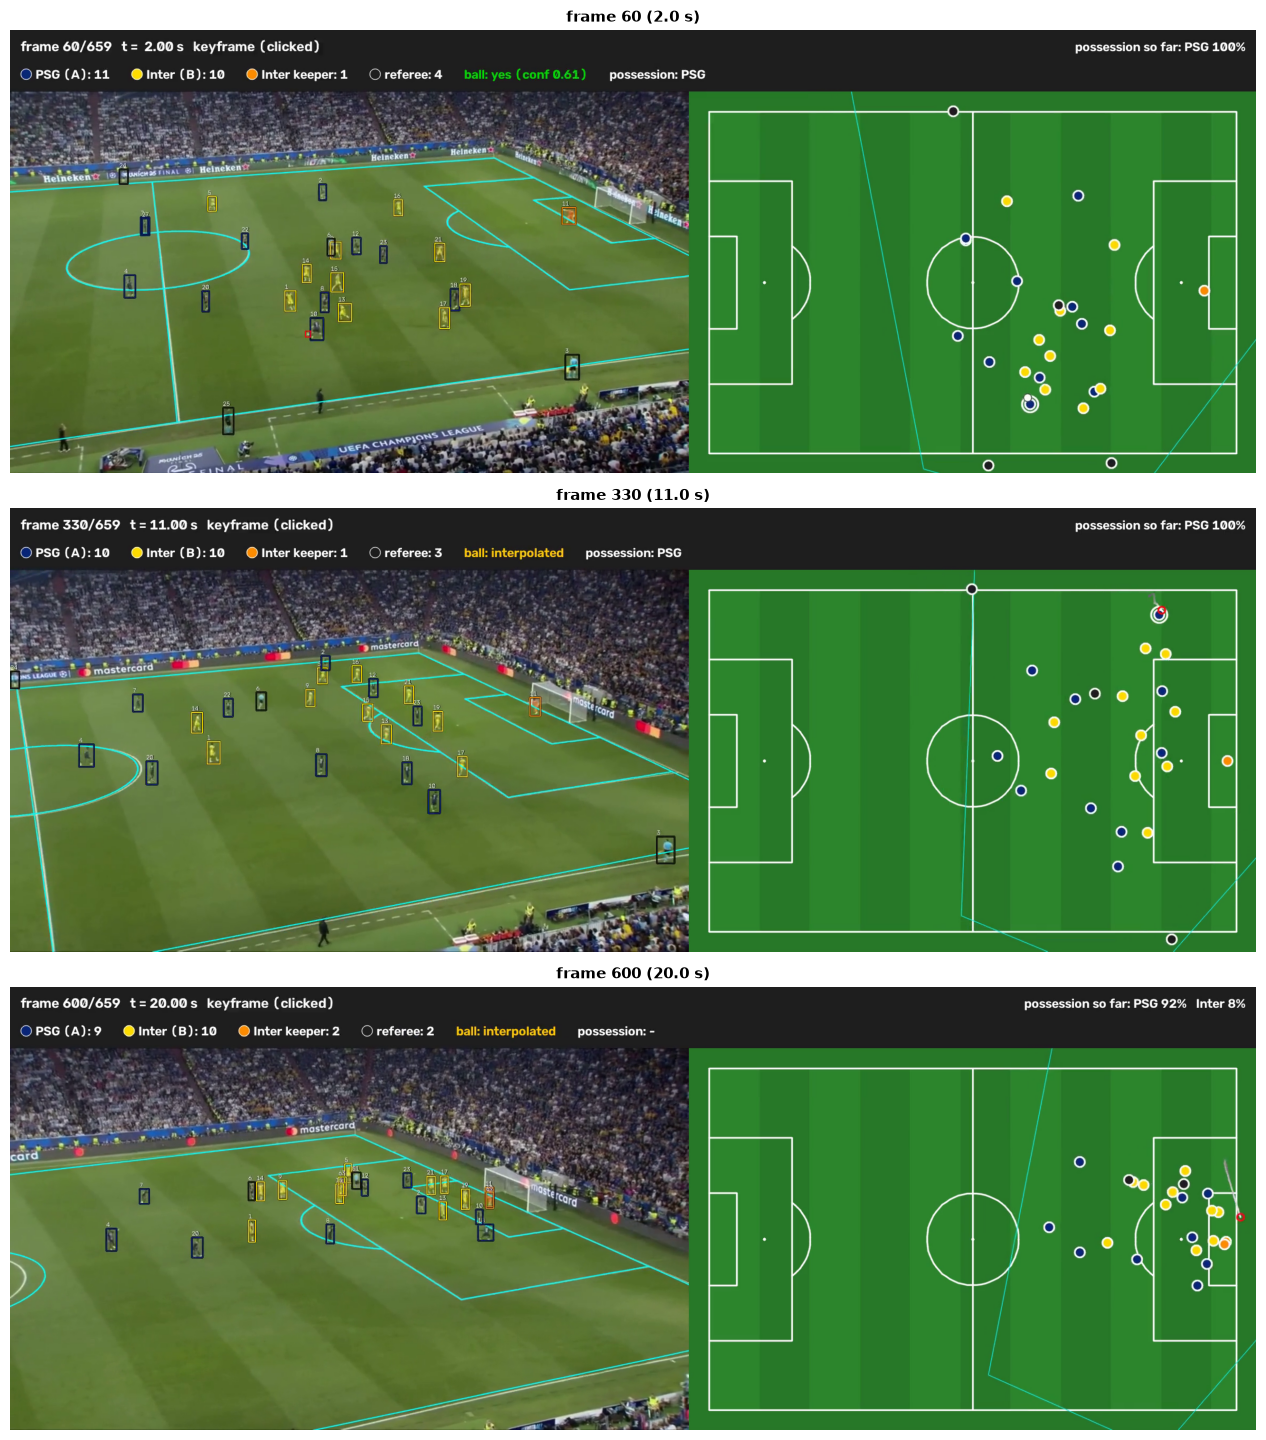

In [4]:
cap = cv2.VideoCapture(str(video_path))
n_frames, fps = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), cap.get(cv2.CAP_PROP_FPS)
w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
print(f"{video_path.name}: {n_frames} frames, {fps:.0f} beelden per seconde, {n_frames / fps:.1f} s, {w} x {h} px")
fig, axes = plt.subplots(3, 1, figsize=(13, 14.5))
for ax, idx in zip(axes, (60, n_frames // 2, n_frames - 60)):
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ok, img = cap.read()
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(f"frame {idx} ({idx / fps:.1f} s)"); ax.axis("off")
cap.release()
plt.tight_layout(); plt.show()

In [5]:
Video((Path("..") / "streamlit" / "output" / video_path.name).as_posix(), embed=False, width=960)

## 3. De kerncijfers van deze run

In [6]:
tracks = pd.read_csv(OUTPUT_DIR / f"tracks_{model_name}.csv")
frames = pd.read_csv(OUTPUT_DIR / f"frames_{model_name}.csv")
states = frames.ball_state.value_counts()
poss = frames.possession_team.value_counts()
n_poss = int(poss.get("A", 0) + poss.get("B", 0))
summary = pd.DataFrame({"waarde": [
    frames.frame.nunique(), tracks.track_id.nunique(),
    int(states.get("detected", 0)), int(states.get("interpolated", 0)), int(states.get("none", 0)),
    f"{100 * poss.get('A', 0) / max(n_poss, 1):.0f} %", f"{100 * poss.get('B', 0) / max(n_poss, 1):.0f} %"]},
    index=["frames", "track-ID's", "frames met gedetecteerde bal", "frames met geïnterpoleerde bal", "frames zonder bal",
           "balbezit PSG (van de frames met bezit)", "balbezit Inter (van de frames met bezit)"])
display(summary)

,waarde
frames,660
track-ID's,41
frames met gedetecteerde bal,308
frames met geïnterpoleerde bal,191
frames zonder bal,161
balbezit PSG (van de frames met bezit),92 %
balbezit Inter (van de frames met bezit),8 %


## 4. Het rapport

Het volledige rapport, zoals het in `streamlit/output/` staat.

In [7]:
display(Markdown(report_path.read_text(encoding="utf-8")))

# Rapport wedstrijdanalyse (psg_vs_inter_CV)

## Samenvatting
- Clip: 22.0 s, 660 verwerkte frames, 29 tracks van minstens 1 s.
- Balbezit: PSG 92%, Inter 8%, 3 wissels.
- PSG valt aan richting rechter doel (x=105) (betrouwbaarheid hoog).
- Aanvallen (bal in laatste derde): PSG 5, Inter 0; ingangen 16 m-gebied: PSG 4, Inter 0.
- Totaal gelopen (ondergrens): PSG 0.51 km, Inter 0.57 km.

Gegenereerd met `run_all.py` (gewichten psg_vs_inter_CV.pt, imgsz 1280, stride 1).

## Balbezit
- Frames met balbezit: 479 van 660
- Aandeel PSG (A): 92%, Inter (B): 8%; wissels: 3

## Afstand en snelheid per team

| team | n_tracks | total_distance_m | mean_distance_m | mean_kmh | max_kmh |
|---|---|---|---|---|---|
| PSG (A) | 11 | 511.5 | 46.5 | 8.11 | 31.2 |
| Inter (B) | 12 | 569.6 | 47.5 | 8.27 | 24.8 |

Per track: zie `analytics/players_psg_vs_inter_CV.csv`.

## Snelheidszones
Zones (bij benadering de gangbare voetbaldrempels; er is geen officiële standaard): stilstaand < 2 km/h, wandelen 2-7 km/h, joggen 7-15 km/h, lopen 15-20 km/h, sprint > 20 km/h. Een sprint = minstens 1 s aaneengesloten boven 20 km/h. Snelheid uit afgevlakte posities per stap.

| team | tracks | stilstaand (< 2 km/h) | wandelen (2-7 km/h) | joggen (7-15 km/h) | lopen (15-20 km/h) | sprint (> 20 km/h) | afstand sprint (m) | sprints |
|---|---|---|---|---|---|---|---|---|
| PSG (A) | 11 | 9 s (4%) | 99 s (46%) | 85 s (40%) | 17 s (8%) | 6 s (3%) | 39.9 | 2 |
| Inter (B) | 12 | 16 s (7%) | 98 s (40%) | 105 s (43%) | 19 s (8%) | 5 s (2%) | 29.2 | 2 |

![snelheidszones PSG (A)](analytics/zones_team_A_psg_vs_inter_CV.png)

![snelheidszones Inter (B)](analytics/zones_team_B_psg_vs_inter_CV.png)

Per track (tijd in s per zone):

| track_id | team | time_standing_s | time_walking_s | time_jogging_s | time_running_s | time_sprinting_s | n_sprints |
|---|---|---|---|---|---|---|---|
| 1 | B | 2.53 | 9.27 | 10.17 | 0.0 | 0.0 | 0 |
| 2 | A | 0.0 | 4.96 | 9.93 | 4.17 | 2.9 | 2 |
| 3 | - | 5.77 | 4.6 | 6.27 | 0.0 | 0.0 | 0 |
| 4 | A | 0.57 | 17.0 | 4.4 | 0.0 | 0.0 | 0 |
| 5 | B | 1.4 | 6.2 | 9.23 | 2.27 | 2.87 | 2 |
| 6 | - | 1.2 | 10.74 | 5.17 | 4.8 | 0.07 | 0 |
| 7 | A | 2.8 | 9.6 | 7.7 | 1.43 | 0.43 | 0 |
| 8 | A | 1.53 | 14.04 | 5.97 | 0.43 | 0.0 | 0 |
| 9 | B | 0.0 | 7.93 | 10.2 | 3.47 | 0.37 | 0 |
| 10 | A | 0.43 | 4.13 | 11.23 | 4.07 | 0.93 | 0 |
| 11 | B | 6.5 | 13.7 | 1.44 | 0.33 | 0.0 | 0 |
| 12 | A | 0.7 | 5.1 | 12.03 | 3.27 | 0.87 | 0 |
| 13 | B | 0.97 | 7.17 | 11.63 | 2.2 | 0.0 | 0 |
| 14 | B | 0.5 | 7.63 | 12.73 | 1.1 | 0.0 | 0 |
| 15 | B | 0.23 | 9.33 | 10.67 | 1.73 | 0.0 | 0 |
| 16 | B | 0.0 | 8.5 | 8.17 | 2.73 | 0.73 | 0 |
| 17 | B | 1.13 | 8.8 | 10.7 | 0.6 | 0.73 | 0 |
| 18 | A | 0.3 | 13.03 | 8.63 | 0.0 | 0.0 | 0 |
| 19 | B | 1.2 | 10.26 | 7.47 | 2.97 | 0.0 | 0 |
| 20 | A | 0.03 | 15.43 | 6.23 | 0.23 | 0.03 | 0 |
| 21 | B | 0.93 | 7.4 | 11.83 | 1.8 | 0.0 | 0 |
| 22 | A | 1.1 | 5.97 | 9.0 | 1.03 | 0.0 | 0 |
| 23 | A | 1.3 | 7.87 | 9.9 | 1.97 | 0.93 | 0 |
| 24 | - | 4.33 | 6.47 | 0.53 | 0.0 | 0.0 | 0 |
| 25 | - | 3.77 | 2.2 | 0.0 | 0.0 | 0.0 | 0 |
| 27 | A | 0.07 | 1.63 | 0.03 | 0.0 | 0.0 | 0 |
| 51 | - | 0.0 | 1.1 | 2.07 | 1.43 | 0.27 | 0 |
| 63 | B | 0.83 | 1.77 | 0.5 | 0.07 | 0.0 | 0 |
| 74 | - | 0.0 | 0.03 | 0.0 | 0.77 | 0.3 | 0 |

## Kilometers
| team | tracks | totaal km (ondergrens) | gem. km per track | km per speler per 90 min (indicatief) | cliplengte (s) |
|---|---|---|---|---|---|
| PSG (A) | 11 | 0.511 | 0.046 | 12.2 | 22.0 |
| Inter (B) | 12 | 0.57 | 0.047 | 12.4 | 22.0 |

Dit is een **ondergrens**: een ID-switch splitst een speler over meerdere tracks, tracks korter dan de minimumduur vallen weg en een speler telt alleen mee zolang hij getrackt wordt. De waarde per 90 minuten schaalt de afstandsratio van een clip van 22 s op en is **alleen indicatief**: een korte clip zegt weinig over een hele wedstrijd.

## Aanvalsrichting en aanvallen
- **PSG valt aan richting rechter doel (x=105)**; Inter valt aan richting linker doel (x=0).
- Betrouwbaarheid: **hoog** (3 van 3 signalen eens).
- Keepers (gem. x in m): {'B': 100.9} -> signaal +1
- Gemiddelde x veldspelers (m): {'A': 74.9, 'B': 81.4} -> signaal +1 (zwak bewijs)
- Netto balverplaatsing in x bij balbezit (m): {'A': 18.8, 'B': 9.3} -> signaal +1
- Signaal +1 = PSG valt naar rechts aan (x=105), -1 = naar links (x=0), 0 = geen uitspraak; de keeper telt dubbel.

| team | balbezitfases | ingangen laatste derde | aanvallen | ingangen 16 m-gebied |
|---|---|---|---|---|
| PSG (A) | 5 | 5 | 5 | 4 |
| Inter (B) | 2 | 0 | 0 | 0 |

Aanval = balbezitsfase waarin de bal het laatste derde (binnen 35 m van de aangevallen doellijn) binnenkomt; ingang 16 m-gebied = bal in het strafschopgebied (16,5 m x 40,3 m). **Schoten** zijn bewust niet geteld: ze zijn in deze trackingdata niet betrouwbaar van passes te onderscheiden.

## Heatmaps en posities
De pijl op de teamheatmaps toont de aanvalsrichting.

![heatmap PSG](analytics/heatmap_team_A_psg_vs_inter_CV.png)

![heatmap Inter](analytics/heatmap_team_B_psg_vs_inter_CV.png)

![heatmap bal](analytics/heatmap_ball_psg_vs_inter_CV.png)

![gemiddelde posities](analytics/average_positions_psg_vs_inter_CV.png)

## Video
Minimapvideo: [minimap_psg_vs_inter_CV.mp4](minimap_psg_vs_inter_CV.mp4)

## Systeemevaluatie (tegen eigen ground truth)

### Spelers op het lichaam geklikt (anchor body)

- Gelabelde frames: 22, vergeleken: 22
- Spelers: precision 0.979, recall 0.992, F1 0.986 (TP 512, FP 11, FN 4)
- Teams: nauwkeurigheid 0.992, rol 0.992 (n=512)
- Bal: detectiegraad 0.88, positiefout mediaan 0.26 m (n=15), binnen 3 m: 0.93
- Balbezit: nauwkeurigheid 0.77 (n=22)
- Tracking: 71 ID-switches (grove schatting), IDF1-lite 0.58

Volledig rapport: [system_eval_psg_vs_inter_CV_body.md](evaluation/system_eval_psg_vs_inter_CV_body.md)

### Spelers op de voeten geklikt (anchor feet)

- Gelabelde frames: 6, vergeleken: 6
- Spelers: precision 0.979, recall 1.000, F1 0.989 (TP 140, FP 3, FN 0)
- Positiefout spelers: mediaan 1.03 m, gemiddeld 1.09 m, p90 1.77 m
- Teams: nauwkeurigheid 0.993, rol 0.993 (n=140)
- Bal: detectiegraad 1.00, positiefout mediaan 0.16 m (n=4), binnen 3 m: 1.00
- Balbezit: nauwkeurigheid 0.67 (n=6)
- Tracking: 36 ID-switches (grove schatting), IDF1-lite 0.37

Volledig rapport: [system_eval_psg_vs_inter_CV_feet.md](evaluation/system_eval_psg_vs_inter_CV_feet.md)

## Beperkingen
- Eén korte clip (±22 s) van één wedstrijd: geen algemene uitspraken; afstanden en zones gaan over seconden.
- Homografie geldt alleen voor punten op het veld; positieruis wordt afgevlakt maar blijft een foutbron.
- ID-switches splitsen spelers over meerdere tracks en korte tracks vallen weg: kilometers zijn een ondergrens.
- Waarden per 90 minuten zijn een ruwe, indicatieve extrapolatie van 22 s.
- Aanvalsrichting = gewogen stem van keeperpositie, gemiddelde positie veldspelers en balrichting; zie de betrouwbaarheid.
- Schoten worden niet geteld (te onbetrouwbaar in trackingdata); aanvallen en ingangen laatste derde/16 m-gebied zijn eenvoudige regels op de balpositie.
- De evaluatie gebruikt maar enkele gelabelde frames, dus de cijfers zijn grof.


## Conclusie

Met dit notebook is de keten rond: notebook 01 levert het model, notebook 02 tot 06 beoordelen en verklaren elke stap, en
hier staat het eindproduct als video, tabellen en rapport. Dezelfde resultaten zijn interactief te bekijken in de
Streamlit-app (`streamlit run app/app.py` vanuit de map `streamlit`).

## Beperkingen

- De video en de cijfers gelden voor deze ene clip van 22 seconden en voor het actieve model.
- De homografie steunt op met de hand geklikte veldpunten voor deze clip (notebook 03).
- De systeemevaluatie in het rapport steunt op 28 handgelabelde frames (notebook 06).